[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beykyle/jitr/blob/main/examples/notebooks/rigid_rotor_coupled_channels.ipynb)

In [1]:
# Google Colab setup: installs jitr into the Colab runtime.
# Does nothing when the notebook is run anywhere else.
import sys

if "google.colab" in sys.modules:
    import subprocess

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "jitr"], check=True)

# Rigid-rotor coupled channels

A deformed target couples the elastic channel to the excited states of its rotational band. Here we set up the two rotor examples of P. Descouvemont, *Comput. Phys. Commun.* **200** (2016) 199 -- $\alpha + {}^{12}$C with the $0^+, 2^+, 4^+$ band (Example 4) and ${}^{16}$O $+ {}^{44}$Ca with $0^+, 2^+$ (Example 3) -- reproduce the published collision matrices, and then compute what the paper does not: the elastic and inelastic cross sections summed over every $J^\pi$.

The potential is a Woods-Saxon $U(r) = -(V + iW) f(r)$ plus the Coulomb potential of a uniformly charged sphere, deformed to first order in $\beta$: the coupling between rotor states is $-\beta R_c U'(r)$ times the geometry returned by `rotor`.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from jitr.reactions import Level, rotor
from jitr.utils.constants import HBARC
from jitr.xs import amplitudes, coupled

E2 = 1.44  # MeV fm, the value of e^2 used in the paper
HBAR2_AMU = 20.736  # MeV fm^2, hbar^2 / (amu), as in the paper

## The model

Every level of the band is a `Level` with its spin and parity. The workspace enumerates the channels $(l, I)$ of each $J^\pi$ block, solves every block at every energy, and needs the wavenumber, reduced mass and Sommerfeld parameter of each level: below a threshold $k^2 < 0$ and the channel is closed.

In [3]:
class Rotor:
    """A projectile on a rigid-rotor target, in the units of the paper."""

    def __init__(self, Ap, At, Zp, Zt, levels, beta, V=110.0, W=20.0, a=0.5):
        self.mass_factor = HBAR2_AMU / (Ap * At / (Ap + At))  # hbar^2 / 2 mu
        self.z12 = Zp * Zt * E2
        self.levels = [Level(I) for I, _ in levels]
        self.Ex = np.array([Ex for _, Ex in levels])
        self.R = 1.2 * (Ap ** (1 / 3) + At ** (1 / 3))
        self.Rc = 1.2 * At ** (1 / 3)  # coupling radius
        self.beta, self.depth, self.a = beta, V + 1j * W, a

    def workspace(self, energies, a, nbasis, lmax, **blocks):
        k2 = (np.atleast_1d(energies)[:, None] - self.Ex) / self.mass_factor
        mu = np.full_like(k2, HBARC**2 / (2 * self.mass_factor))
        eta = self.z12 / (2 * self.mass_factor * np.sqrt(np.abs(k2)))
        return coupled.Workspace(a, nbasis, self.levels, lmax, k2, mu, eta, **blocks)

    def terms(self, ws):
        r = ws.r
        x = np.exp((r - self.R) / self.a)
        U = -self.depth / (1 + x)
        dU = self.depth * x / (self.a * (1 + x) ** 2)
        coulomb = np.where(
            r <= self.R, self.z12 * (3 - (r / self.R) ** 2) / (2 * self.R), self.z12 / r
        )
        geometry = rotor(ws.blocks, self.levels, 2)
        return [(np.eye(ws.nch), U + coulomb), (geometry, -self.beta * self.Rc * dU)]


alpha_c12 = Rotor(4, 12, 2, 6, [(0, 0.0), (2, 4.44), (4, 14.08)], beta=0.58)
o16_ca44 = Rotor(16, 44, 8, 20, [(0, 0.0), (2, 1.156)], beta=0.4)

## $J^\pi$ blocks

For $\alpha + {}^{12}$C the blocks hold between 3 and 9 channels. To solve them all with one vectorized call, smaller blocks are padded with inert channels; they are masked out of every result.

In [4]:
ws = alpha_c12.workspace(20.0, a=11.0, nbasis=60, lmax=20)
b = ws.blocks
for n in range(6):
    channels = [
        f"(l={l}, I={ws.levels[lv].I:.0f})"
        for l, lv, active in zip(b.l[n], b.level[n], b.active[n], strict=True)
        if active
    ]
    parity = "+" if b.parity[n] > 0 else "-"
    print(f"J = {b.J[n]:.0f}{parity}: {len(channels)} channels {' '.join(channels)}")
print(f"... {b.J.size} blocks, all padded to {ws.nch} channels")

J = 0+: 3 channels (l=0, I=0) (l=2, I=2) (l=4, I=4)
J = 1+: 2 channels (l=2, I=2) (l=4, I=4)
J = 1-: 5 channels (l=1, I=0) (l=1, I=2) (l=3, I=2) (l=3, I=4) (l=5, I=4)
J = 2+: 7 channels (l=2, I=0) (l=0, I=2) (l=2, I=2) (l=4, I=2) (l=2, I=4) (l=4, I=4) (l=6, I=4)
J = 2-: 4 channels (l=1, I=2) (l=3, I=2) (l=3, I=4) (l=5, I=4)
J = 3+: 5 channels (l=2, I=2) (l=4, I=2) (l=2, I=4) (l=4, I=4) (l=6, I=4)
... 48 blocks, all padded to 9 channels


## Reproducing the paper

The paper tabulates, for one $J^\pi$, the modulus and half the phase of the first column of the collision matrix -- the amplitudes for elastic scattering and for exciting each open channel. A single R-matrix interval at the published channel radius reproduces them.

In [5]:
def first_column(model, energies, J, parity, a, nbasis):
    ws = model.workspace(energies, a, nbasis, lmax=J + 4, J=[J], parity=parity)
    S, is_open = ws.smatrix(local=model.terms(ws))
    out = []
    for e in range(len(energies)):
        n = int(is_open[e, 0].sum())
        column = np.asarray(S[e, 0, :n, 0])
        out.append((np.abs(column), np.angle(column) / 2))
    return out


# Descouvemont (2016), Example 3 (a = 14 fm) and Example 4 (a = 11 fm)
published = {
    "16O + 44Ca, J = 30+, E = 44 MeV": (
        [0.53757, 0.16177, 0.20848, 0.21177],
        [0.1836, 0.24808, 0.034417, -0.076024],
    ),
    "alpha + 12C, J = 3-, E = 20 MeV": (
        [
            0.028037,
            0.019167,
            0.01908,
            0.020027,
            0.0047582,
            0.0063842,
            0.0094671,
            0.0058584,
        ],
        [-0.41741, -0.51378, 0.42378, 1.052, 0.77293, 1.3273, 1.467, 1.288],
    ),
}
ours = {
    "16O + 44Ca, J = 30+, E = 44 MeV": first_column(o16_ca44, [44.0], 30, 1, 14.0, 100)[
        0
    ],
    "alpha + 12C, J = 3-, E = 20 MeV": first_column(alpha_c12, [20.0], 3, -1, 11.0, 80)[
        0
    ],
}
for case, (amp, phase) in published.items():
    print(case)
    print("  |S_c0|  jitr   ", np.round(ours[case][0], 5))
    print("          paper  ", np.array(amp))
    print("  phase   jitr   ", np.round(ours[case][1], 4))
    print("          paper  ", np.array(phase))

16O + 44Ca, J = 30+, E = 44 MeV
  |S_c0|  jitr    [0.53757 0.16177 0.20848 0.21177]
          paper   [0.53757 0.16177 0.20848 0.21177]
  phase   jitr    [ 0.1836  0.2481  0.0344 -0.076 ]
          paper   [ 0.1836    0.24808   0.034417 -0.076024]
alpha + 12C, J = 3-, E = 20 MeV
  |S_c0|  jitr    [0.02804 0.01917 0.01908 0.02003 0.00476 0.00638 0.00947 0.00586]
          paper   [0.028037  0.019167  0.01908   0.020027  0.0047582 0.0063842 0.0094671
 0.0058584]
  phase   jitr    [-0.4174 -0.5138  0.4238  1.052   0.7729  1.3273  1.467   1.288 ]
          paper   [-0.41741 -0.51378  0.42378  1.052    0.77293  1.3273   1.467    1.288  ]


At 4, 8 and 12 MeV some $\alpha + {}^{12}$C channels are closed. There the published values, computed with subinterval propagation, change with the partition into intervals; the single-interval values are converged in the basis size and independent of the channel radius, and agree with a direct integration of the coupled equations (see `tests/benchmarks`).

## Opening channels

Scanning the energy across the $2^+$ (4.44 MeV) and $4^+$ (14.08 MeV) thresholds: each inelastic channel of the $J^\pi = 3^-$ block appears in the first column of the collision matrix once it opens. Closed channels have no row in the collision matrix (it is zero there). One workspace covers all the energies.

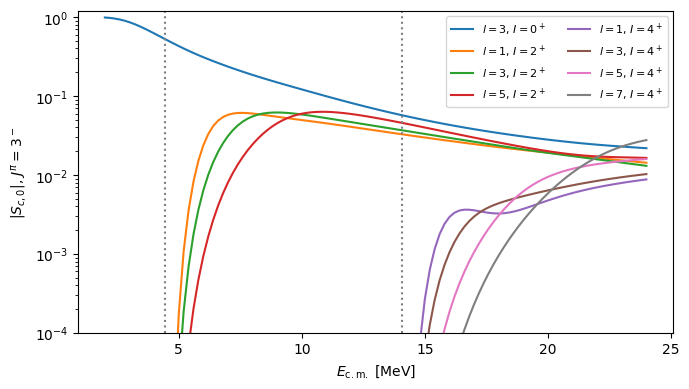

In [6]:
energies = np.linspace(2.0, 24.0, 111)
ws = alpha_c12.workspace(energies, a=11.0, nbasis=80, lmax=7, J=[3], parity=-1)
S, is_open = ws.smatrix(local=alpha_c12.terms(ws))
S = np.asarray(S[:, 0])

fig, ax = plt.subplots(figsize=(7, 4))
for c in range(ws.blocks.active[0].sum()):
    l, I = ws.blocks.l[0, c], ws.levels[ws.blocks.level[0, c]].I
    ax.plot(energies, np.abs(S[:, c, 0]), label=f"$l={l}$, $I={I:.0f}^+$")
for E in alpha_c12.Ex[1:]:
    ax.axvline(E, color="gray", ls=":")
ax.set_yscale("log")
ax.set_ylim(1e-4, 1.2)
ax.set_xlabel(r"$E_{\rm c.m.}$ [MeV]")
ax.set_ylabel(r"$|S_{c,0}|$, $J^\pi = 3^-$")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## Elastic and inelastic cross sections

Summing all $J^\pi$ blocks gives the angular distributions. `amplitudes.transition_tables` builds, once, the geometry of a transition from an entrance level to an exit level; `amplitudes.observables` then evaluates the cross sections from the collision matrices of every block.

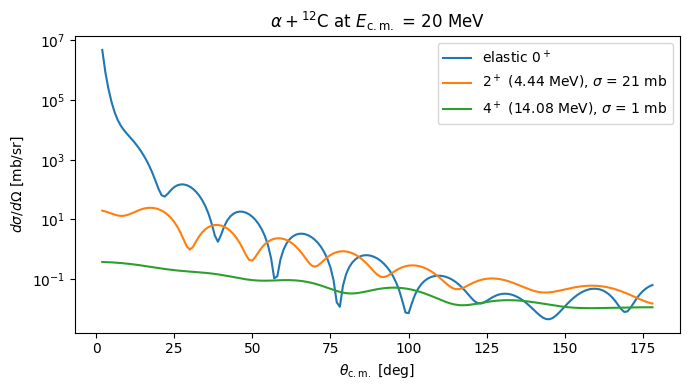

In [7]:
angles = np.linspace(np.radians(2), np.radians(178), 177)
ws = alpha_c12.workspace([20.0], a=11.0, nbasis=80, lmax=24)
S, _ = ws.smatrix(local=alpha_c12.terms(ws))

fig, ax = plt.subplots(figsize=(7, 4))
for exit, label in zip(
    range(3), ["elastic $0^+$", "$2^+$ (4.44 MeV)", "$4^+$ (14.08 MeV)"], strict=True
):
    geometry = amplitudes.transition_geometry(ws, 0, exit)
    xs = amplitudes.observables(S, amplitudes.transition_tables(ws, geometry, angles))
    ax.plot(
        np.degrees(angles),
        xs.dsdo[0],
        label=f"{label}, $\\sigma$ = {xs.sigma[0]:.0f} mb" if exit else label,
    )
ax.set_yscale("log")
ax.set_xlabel(r"$\theta_{\rm c.m.}$ [deg]")
ax.set_ylabel(r"$d\sigma/d\Omega$ [mb/sr]")
ax.set_title(r"$\alpha + {}^{12}$C at $E_{\rm c.m.}$ = 20 MeV")
ax.legend()
plt.tight_layout()
plt.show()

The deformation parameter could be calibrated like any other parameter: it enters only through the radial form factor $-\beta R_c U'(r)$, so the cross sections are differentiable in $\beta$ with `jax.grad`.